# AirGuard AI: Machine Learning-Based Air Quality Classification and Pollution Pattern Detection

**Data Science Minor Project**

---
## Section 1: Introduction

### Problem Statement
Air pollution is a serious problem in many Indian cities. Monitoring stations measure different pollutants, but it is hard to understand the pollution level just by looking at raw numbers. This project uses machine learning to:
1. **Classify** the PM2.5 pollution level of a monitoring station into categories (Good, Satisfactory, Moderate, Poor, Very Poor, Severe).
2. **Predict** the PM2.5 value of a station (a number) from the other pollutants.
3. **Detect patterns** by grouping stations with similar pollution behaviour.

### Objectives
- Clean and prepare the air quality data.
- Explore the data with graphs (EDA).
- Predict the PM2.5 value using **Linear Regression** and check it with MAE, MSE, RMSE and R-squared.
- Classify PM2.5 pollution categories using **Logistic Regression**, **K-Nearest Neighbors (KNN)** and **Decision Tree**, and check them with the confusion matrix and F1-score.
- Group stations using **K-Means Clustering** and explain the clusters.
- Explain the results of each model in simple words.

### About the Dataset
The file `IndianGovernmentAirQualityData.csv` has air quality readings from Government of India monitoring stations. Each row is **one pollutant at one station** (so a station has up to 7 rows). Main columns:

| Column | Meaning |
|---|---|
| state, city, station | Location of the monitoring station |
| latitude, longitude | Coordinates of the station |
| last_update | Time of the reading |
| pollutant_id | Pollutant name (PM2.5, PM10, NO2, SO2, CO, OZONE, NH3) |
| pollutant_min, pollutant_max, pollutant_avg | Minimum, maximum and average reading |

**Important:** the data is a **single snapshot** (one time stamp), not a history over many days. So this project only studies the *current pollution pattern*. It does **not** predict future pollution.

### Why is Air Pollution Analysis Important?
- Pollutants like PM2.5 and PM10 enter the lungs and cause breathing and heart diseases.
- It helps authorities find the most polluted areas and take action.
- It helps people know when outdoor activity is unsafe.

---
## Section 2: Import Libraries

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# scikit-learn tools
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.cluster import KMeans

# Regression metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
# Classification metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

sns.set_style('whitegrid')
print('All libraries imported successfully')

All libraries imported successfully


---
## Section 3: Load the Dataset
Keep the CSV file in the **same folder** as this notebook. (In Google Colab, upload the CSV file first using the Files panel on the left.)

In [36]:
# Load the CSV file (pandas reads the text 'NA' as a missing value automatically)
df = pd.read_csv('IndianGovernmentAirQualityData.csv')

# First five rows
df.head()

,country,state,city,station,last_update,latitude,longitude,pollutant_id,pollutant_min,pollutant_max,pollutant_avg
0,India,Bihar,Samastipur,"DM Office_Kasipur, Samastipur - BSPCB",28-10-2026 14:00,25.859655,85.779440,CO,1.0,8.0,4.0
1,India,Bihar,Sasaram,"Dada Peer, Sasaram - BSPCB",28-10-2026 14:00,24.952822,84.002396,NO2,NaN,NaN,NaN
2,India,Bihar,Sitamarhi,"Dumra, Sitamardhi - BSPCB",28-10-2026 14:00,26.568547,85.517364,OZONE,2.0,96.0,47.0
3,India,Bihar,Siwan,"Chitragupta Nagar, Siwan - BSPCB",28-10-2026 14:00,26.227166,84.357043,PM2.5,67.0,287.0,166.0
4,India,Bihar,Siwan,"Chitragupta Nagar, Siwan - BSPCB",28-10-2026 14:00,26.227166,84.357043,PM10,75.0,156.0,119.0


In [37]:
# Number of rows and columns
print('Rows    :', df.shape[0])
print('Columns :', df.shape[1])

# Column names
print('\nColumn names:')
print(list(df.columns))

Rows    : 3822
Columns : 11

Column names:
['country', 'state', 'city', 'station', 'last_update', 'latitude', 'longitude', 'pollutant_id', 'pollutant_min', 'pollutant_max', 'pollutant_avg']


In [38]:
# Data types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3822 entries, 0 to 3821
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   country        3822 non-null   object 
 1   state          3822 non-null   object 
 2   city           3822 non-null   object 
 3   station        3822 non-null   object 
 4   last_update    3822 non-null   object 
 5   latitude       3822 non-null   float64
 6   longitude      3822 non-null   float64
 7   pollutant_id   3822 non-null   object 
 8   pollutant_min  3519 non-null   float64
 9   pollutant_max  3519 non-null   float64
 10  pollutant_avg  3519 non-null   float64
dtypes: float64(5), object(6)
memory usage: 328.6+ KB


In [39]:
# Basic statistics of the numeric columns
df.describe()

,latitude,longitude,pollutant_min,pollutant_max,pollutant_avg
count,3822.000000,3822.000000,3519.000000,3519.000000,3519.000000
mean,23.536420,78.548920,26.590509,78.671498,49.049162
std,5.069383,4.804498,28.774954,93.708744,55.013427
min,8.514909,70.776774,0.000000,0.000000,0.000000
25%,19.235581,75.644272,6.000000,16.000000,12.000000
50%,24.793951,77.288278,16.000000,44.000000,30.000000
75%,28.389109,80.327067,37.000000,102.000000,65.000000
max,34.147096,94.636574,179.000000,500.000000,405.000000


---
## Section 4: Data Preprocessing
Steps in this section:
1. Check missing values and duplicates.
2. Convert the reading columns to numbers.
3. Remove rows with no reading.
4. Reshape the data so that **one row = one station**.

In [40]:
# Step 1: missing values and duplicates
print('Missing values in each column:')
print(df.isnull().sum())

print('\nFully duplicated rows:', df.duplicated().sum())
print('Duplicate (station + pollutant) rows:', df.duplicated(subset=['station', 'pollutant_id']).sum())

Missing values in each column:
country            0
state              0
city               0
station            0
last_update        0
latitude           0
longitude          0
pollutant_id       0
pollutant_min    303
pollutant_max    303
pollutant_avg    303
dtype: int64

Fully duplicated rows: 0
Duplicate (station + pollutant) rows: 0


**What we found:** Only the three reading columns (`pollutant_min`, `pollutant_max`, `pollutant_avg`) have missing values. This happens when a sensor did not send a reading. There are no duplicate rows.

In [41]:
# Step 2: make sure the reading columns are numeric
# errors='coerce' turns any bad text (like 'NA') into NaN
for col in ['pollutant_min', 'pollutant_max', 'pollutant_avg']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Columns with only one unique value do not help the analysis
print('Unique values in country    :', df['country'].nunique())
print('Unique values in last_update:', df['last_update'].nunique(), '->', df['last_update'].unique())
print('\nThis confirms the data is a single snapshot.')

Unique values in country    : 1
Unique values in last_update: 1 -> ['28-10-2026 14:00']

This confirms the data is a single snapshot.


In [42]:
# Step 3: remove rows that have no average reading
# We do NOT fill these with made-up numbers, because there is no real measurement.
df_clean = df.dropna(subset=['pollutant_avg']).copy()

print('Rows before cleaning:', len(df))
print('Rows after cleaning :', len(df_clean))

# Quick sanity check: minimum should never be greater than maximum
print('Rows where min > max:', (df_clean['pollutant_min'] > df_clean['pollutant_max']).sum())

Rows before cleaning: 3822
Rows after cleaning : 3519
Rows where min > max: 0


**Reshaping (long to wide):** In the original file every pollutant has its own row. For machine learning we need **one row per station** with a separate column for each pollutant. We use `pivot_table` with station, city, state and coordinates as the index, so each pollutant reading is matched to the **correct station**. The `pollutant_avg` value is used.

In [43]:
# Step 4: one row per station, one column per pollutant
pollutants = ['PM2.5', 'PM10', 'NO2', 'SO2', 'CO', 'OZONE', 'NH3']

wide = df_clean.pivot_table(index=['state', 'city', 'station', 'latitude', 'longitude'],
                            columns='pollutant_id',
                            values='pollutant_avg')
wide = wide.reset_index()
wide.columns.name = None

print('Shape of the reshaped data:', wide.shape)
print('\nMissing values per pollutant column (some stations do not measure every pollutant):')
print(wide[pollutants].isnull().sum())
wide.head()

Shape of the reshaped data: (546, 12)

Missing values per pollutant column (some stations do not measure every pollutant):
PM2.5    38
PM10     49
NO2      35
SO2      51
CO       15
OZONE    30
NH3      85
dtype: int64


,state,city,station,latitude,longitude,CO,NH3,NO2,OZONE,PM10,PM2.5,SO2
0,Andhra Pradesh,Amaravati,"Secretariat, Amaravati - APPCB",16.515083,80.518167,20.0,4.0,17.0,27.0,58.0,28.0,14.0
1,Andhra Pradesh,Anantapur,"Gulzarpet, Anantapur - APPCB",14.675886,77.593027,26.0,4.0,18.0,28.0,71.0,83.0,12.0
2,Andhra Pradesh,Chittoor,"Gangineni Cheruvu, Chittoor - APPCB",13.204880,79.097889,20.0,NaN,NaN,49.0,NaN,NaN,NaN
3,Andhra Pradesh,Guntur,"Rajendra Nagar North, Guntur - APPCB",16.316553,80.413302,28.0,6.0,28.0,23.0,61.0,58.0,11.0
4,Andhra Pradesh,Kadapa,"Yerramukkapalli, Kadapa - APPCB",14.465052,78.824187,27.0,2.0,22.0,31.0,59.0,59.0,12.0


---
## Section 5: Exploratory Data Analysis (EDA)

### 5.1 Distribution of each pollutant

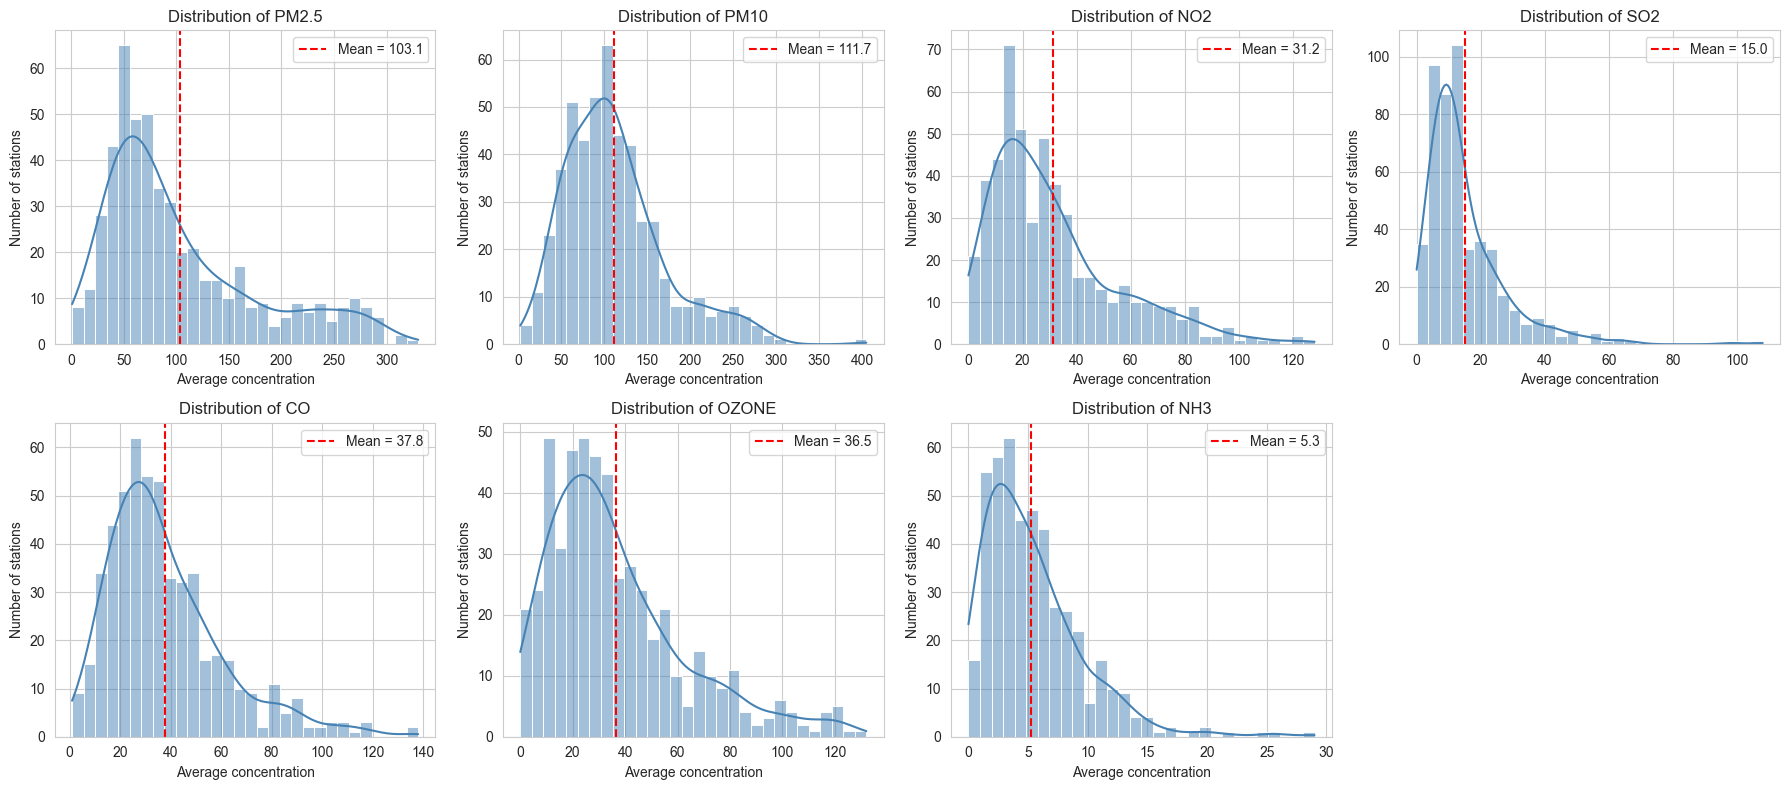

In [44]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for i, p in enumerate(pollutants):
    data = wide[p].dropna()
    sns.histplot(data, bins=30, kde=True, color='steelblue', ax=axes[i])
    axes[i].axvline(data.mean(), color='red', linestyle='--', label='Mean = ' + str(round(data.mean(), 1)))
    axes[i].set_title('Distribution of ' + p)
    axes[i].set_xlabel('Average concentration')
    axes[i].set_ylabel('Number of stations')
    axes[i].legend()

axes[7].axis('off')   # last empty box
plt.tight_layout()
plt.show()

**Explanation:** The particle pollutants (PM2.5 and PM10) are spread over a wide range and are skewed to the right, which means most stations have moderate values but a few stations have very high pollution. Gases like SO2 and NH3 have mostly low values.

### 5.2 Number of records for each pollutant

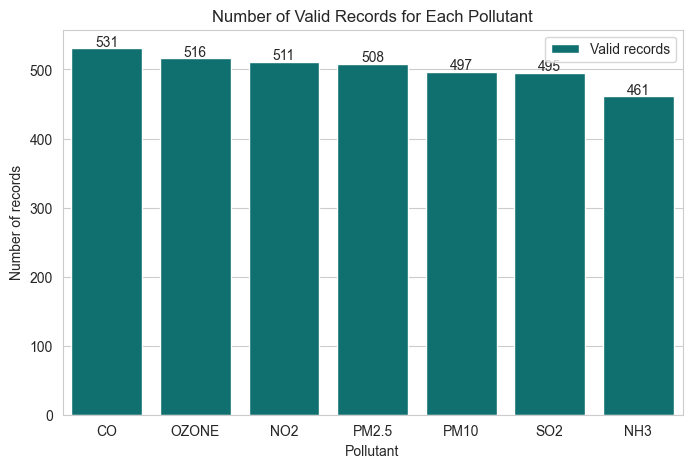

In [45]:
record_counts = df_clean['pollutant_id'].value_counts()

plt.figure(figsize=(8, 5))
ax = sns.barplot(x=record_counts.index, y=record_counts.values, color='teal', label='Valid records')
for i, v in enumerate(record_counts.values):
    ax.text(i, v + 3, str(v), ha='center')
plt.title('Number of Valid Records for Each Pollutant')
plt.xlabel('Pollutant')
plt.ylabel('Number of records')
plt.legend()
plt.show()

**Explanation:** The total number of stations is 546, but not all stations have a valid reading for every pollutant. NH3 has the fewest valid records (461), while CO has the most (531).

### 5.3 Comparison of pollutant concentrations

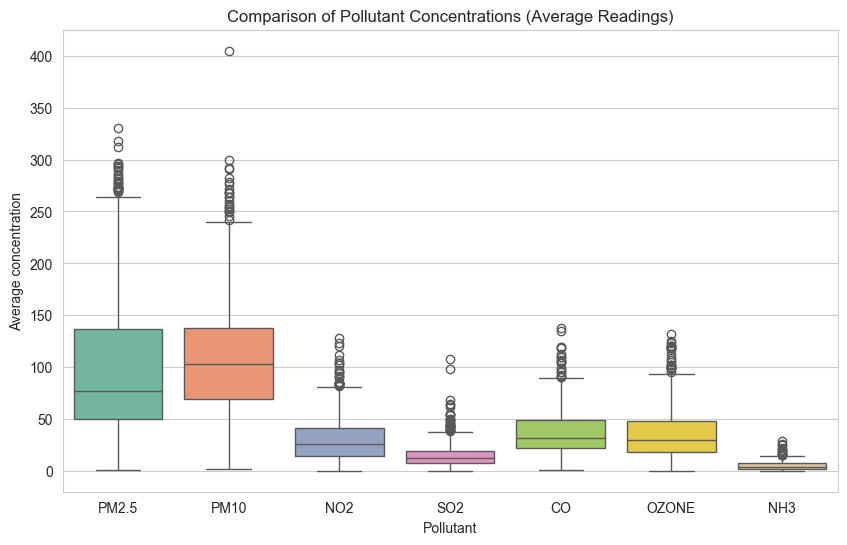

Mean value of each pollutant:
PM2.5    103.14
PM10     111.67
NO2       31.21
SO2       14.99
CO        37.82
OZONE     36.48
NH3        5.28
dtype: float64


In [46]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=wide[pollutants], palette='Set2')
plt.title('Comparison of Pollutant Concentrations (Average Readings)')
plt.xlabel('Pollutant')
plt.ylabel('Average concentration')
plt.show()

print('Mean value of each pollutant:')
print(wide[pollutants].mean().round(2))

**Explanation:** PM10 and PM2.5 have the highest values and the biggest spread, so particulate matter is the main concern in this dataset. Note that different pollutants are reported in different units, so this graph is only a rough comparison of the spread and the level.

### 5.4 Missing-value visualization

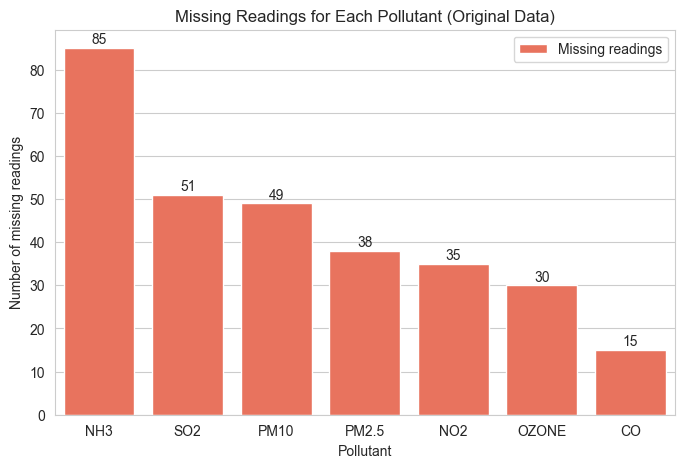

In [47]:
# Missing readings per pollutant in the ORIGINAL data (before cleaning)
missing_counts = df[df['pollutant_avg'].isnull()]['pollutant_id'].value_counts()

plt.figure(figsize=(8, 5))
ax = sns.barplot(x=missing_counts.index, y=missing_counts.values, color='tomato', label='Missing readings')
for i, v in enumerate(missing_counts.values):
    ax.text(i, v + 1, str(v), ha='center')
plt.title('Missing Readings for Each Pollutant (Original Data)')
plt.xlabel('Pollutant')
plt.ylabel('Number of missing readings')
plt.legend()
plt.show()

**Explanation:** Missing readings are spread over all pollutants. NH3 has the most missing values. We removed these rows during cleaning instead of inventing values.

### 5.5 Correlation heatmap

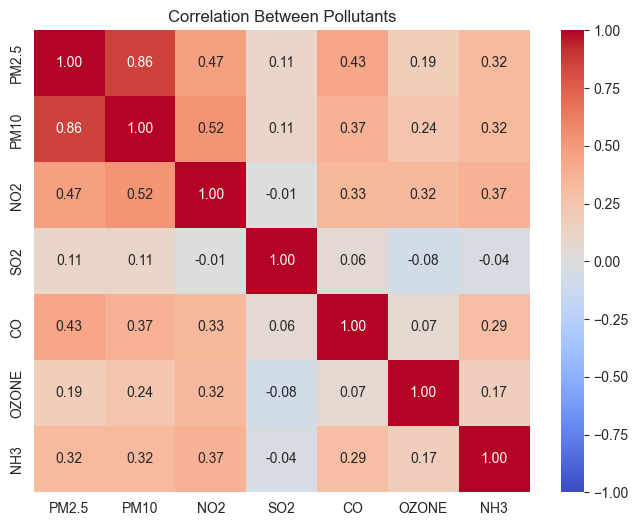

In [48]:
plt.figure(figsize=(8, 6))
sns.heatmap(wide[pollutants].corr(), annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Correlation Between Pollutants')
plt.show()

**Explanation:** PM2.5 and PM10 are strongly and positively correlated, because they are both particles and often come from the same sources (dust, smoke, vehicles). The gases have weaker correlations with the particles.

### 5.6 Comparison of cities

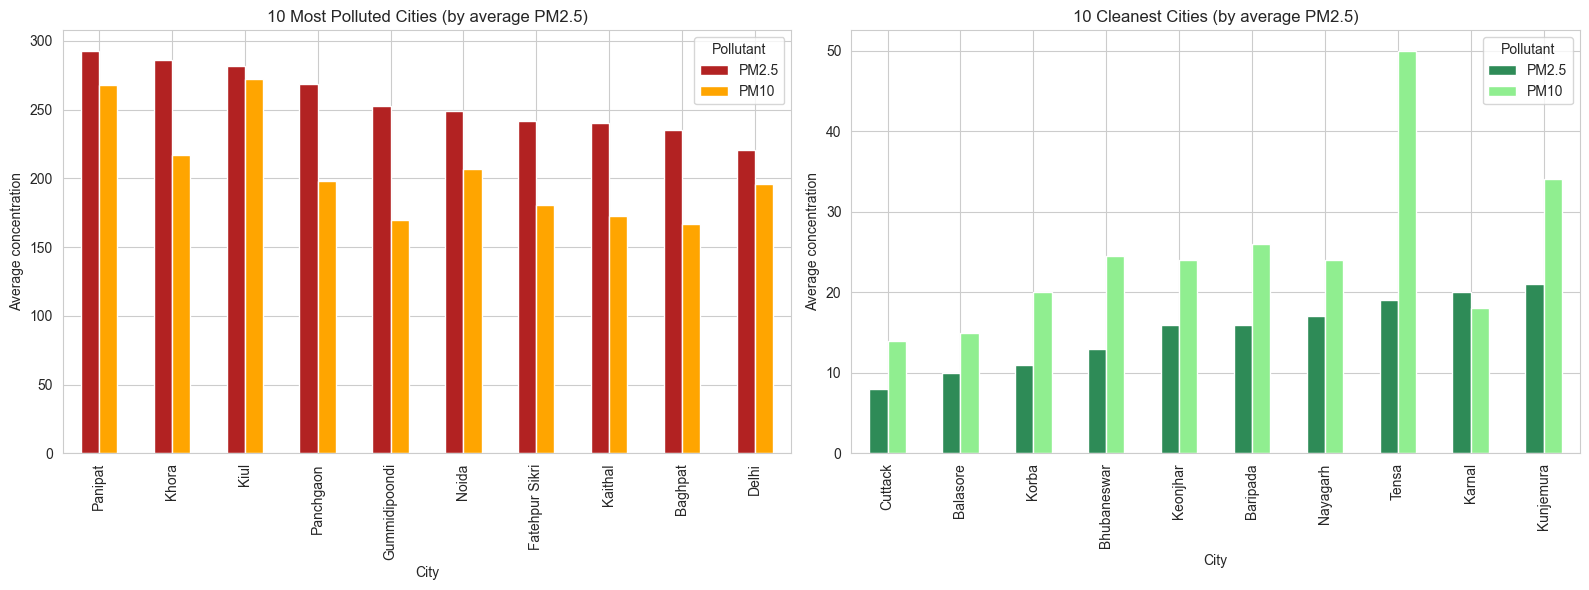

In [49]:
# Average PM2.5 and PM10 for each city (a city may have more than one station)
city_avg = wide.groupby('city')[['PM2.5', 'PM10']].mean().dropna()

top10 = city_avg.sort_values('PM2.5', ascending=False).head(10)
low10 = city_avg.sort_values('PM2.5', ascending=True).head(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

top10.plot(kind='bar', ax=axes[0], color=['firebrick', 'orange'])
axes[0].set_title('10 Most Polluted Cities (by average PM2.5)')
axes[0].set_xlabel('City')
axes[0].set_ylabel('Average concentration')
axes[0].legend(title='Pollutant')

low10.plot(kind='bar', ax=axes[1], color=['seagreen', 'lightgreen'])
axes[1].set_title('10 Cleanest Cities (by average PM2.5)')
axes[1].set_xlabel('City')
axes[1].set_ylabel('Average concentration')
axes[1].legend(title='Pollutant')

plt.tight_layout()
plt.show()

**Explanation:** The graph on the left shows the cities with the highest average PM2.5 and the one on the right shows the cities with the lowest. Some cities have only one station, so their average depends on that single reading.

---
## Section 6: Prepare Data for Modelling

### Creating the target variables
We need two targets:
- **Regression target:** the PM2.5 average value itself (a number) - used by Linear Regression.
- **Classification target:** a PM2.5 pollution category - used by Logistic Regression and KNN.

The categories are made by dividing the **PM2.5 average** into six groups. We use the PM2.5 breakpoints of the Indian National AQI (CPCB):

| PM2.5 average | Category |
|---|---|
| 0 – 30 | Good |
| 31 – 60 | Satisfactory |
| 61 – 90 | Moderate |
| 91 – 120 | Poor |
| 121 – 250 | Very Poor |
| above 250 | Severe |

*Note:* The official AQI uses 24-hour averages. Our file has the latest average reading of one snapshot, so these are **PM2.5 level categories** using the same thresholds, not an official AQI value.

**Avoiding data leakage:** PM2.5 is used to make the targets, so it is **not** used as an input feature. Stations with no PM2.5 reading are removed (no labels are invented).

In [50]:
# Keep only stations that have a PM2.5 reading
pm_data = wide.dropna(subset=['PM2.5']).copy()
print('Stations in total             :', len(wide))
print('Stations with a PM2.5 reading :', len(pm_data))

# Create the PM2.5 category using the thresholds
bins = [0, 30, 60, 90, 120, 250, np.inf]
class_names = ['Good', 'Satisfactory', 'Moderate', 'Poor', 'Very Poor', 'Severe']
pm_data['PM25_Category'] = pd.cut(pm_data['PM2.5'], bins=bins, labels=class_names, include_lowest=True)

print('\nNumber of stations in each category:')
print(pm_data['PM25_Category'].value_counts().reindex(class_names))

Stations in total             : 546
Stations with a PM2.5 reading : 508

Number of stations in each category:
PM25_Category
Good             37
Satisfactory    140
Moderate        118
Poor             64
Very Poor       113
Severe           36
Name: count, dtype: int64


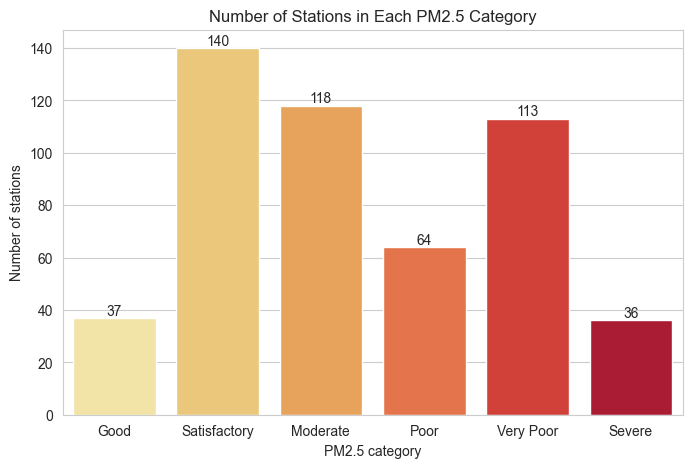

In [51]:
plt.figure(figsize=(8, 5))
ax = sns.countplot(x='PM25_Category', data=pm_data, order=class_names, palette='YlOrRd')
for container in ax.containers:
    ax.bar_label(container)
plt.title('Number of Stations in Each PM2.5 Category')
plt.xlabel('PM2.5 category')
plt.ylabel('Number of stations')
plt.show()

### Input features and train-test split
- **Input features:** PM10, NO2, SO2, CO, OZONE, NH3, latitude and longitude. (PM10 is a separate sensor reading, but it is correlated with PM2.5. We keep it and mention this in the limitations.)
- **Not used:** state, city and station names. They have hundreds of unique values, so encoding them would create too many columns for a simple project. The target is text, which scikit-learn handles directly.
- **Missing values:** Some stations miss a few pollutant readings. We fill them with the **median of the training data**. The median is calculated **only from the training set** to avoid data leakage.
- **Scaling:** Linear Regression, Logistic Regression and KNN work better with scaled features (KNN needs it because it uses distances). The scaler is also fitted only on the training set.
- All supervised models (Linear Regression, Logistic Regression, KNN) use the **same train and test split**.

In [52]:
feature_cols = ['PM10', 'NO2', 'SO2', 'CO', 'OZONE', 'NH3', 'latitude', 'longitude']
X = pm_data[feature_cols]
y = pm_data['PM25_Category'].astype(str)   # target for classification (category)
y_reg = pm_data['PM2.5']                    # target for regression (number)

# 80% training, 20% testing. stratify keeps the category proportions similar in both parts.
# The same rows go to train/test for both targets.
X_train, X_test, y_train, y_test, y_reg_train, y_reg_test = train_test_split(
    X, y, y_reg, test_size=0.2, random_state=42, stratify=y)
print('Training rows:', X_train.shape[0], '| Testing rows:', X_test.shape[0])
print('Missing values in X_train before filling:', X_train.isnull().sum().sum())

# Fill missing values using the median of the TRAINING data only
imputer = SimpleImputer(strategy='median')
X_train_imp = pd.DataFrame(imputer.fit_transform(X_train), columns=feature_cols)
X_test_imp = pd.DataFrame(imputer.transform(X_test), columns=feature_cols)

# Scale the features (fit on training data only)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imp)
X_test_scaled = scaler.transform(X_test_imp)

print('Missing values after filling:', X_train_imp.isnull().sum().sum() + X_test_imp.isnull().sum().sum())

Training rows: 406 | Testing rows: 102
Missing values in X_train before filling: 129
Missing values after filling: 0


---
## Section 7: Linear Regression (predicting the PM2.5 value)
Linear Regression draws the best straight-line relationship between the input features (PM10, NO2, SO2, CO, OZONE, NH3, latitude, longitude) and the **PM2.5 number**. This is a **regression** problem because the answer is a number, not a category.

**Metrics used to check a regression model** (smaller errors are better):

| Metric | Meaning |
|---|---|
| **MAE** (Mean Absolute Error) | Average size of the error, ignoring + or - sign. Easy to understand. |
| **MSE** (Mean Squared Error) | Average of the squared errors. Big errors are punished more. |
| **RMSE** (Root Mean Squared Error) | Square root of MSE. It is in the same unit as PM2.5. |
| **R-squared (R2 score)** | How much of the PM2.5 variation the model explains. 1 is perfect, 0 means no better than guessing the average. |

In [53]:
# Train the model
lin_model = LinearRegression()
lin_model.fit(X_train_scaled, y_reg_train)

# Predict PM2.5 for the test stations
lin_pred = lin_model.predict(X_test_scaled)

# Regression metrics
lin_mae = mean_absolute_error(y_reg_test, lin_pred)
lin_mse = mean_squared_error(y_reg_test, lin_pred)
lin_rmse = np.sqrt(lin_mse)
lin_r2 = r2_score(y_reg_test, lin_pred)

print('Linear Regression Results')
print('MAE  :', round(lin_mae, 2))
print('MSE  :', round(lin_mse, 2))
print('RMSE :', round(lin_rmse, 2))
print('R2   :', round(lin_r2, 4))

Linear Regression Results
MAE  : 27.21
MSE  : 1526.56
RMSE : 39.07
R2   : 0.7073


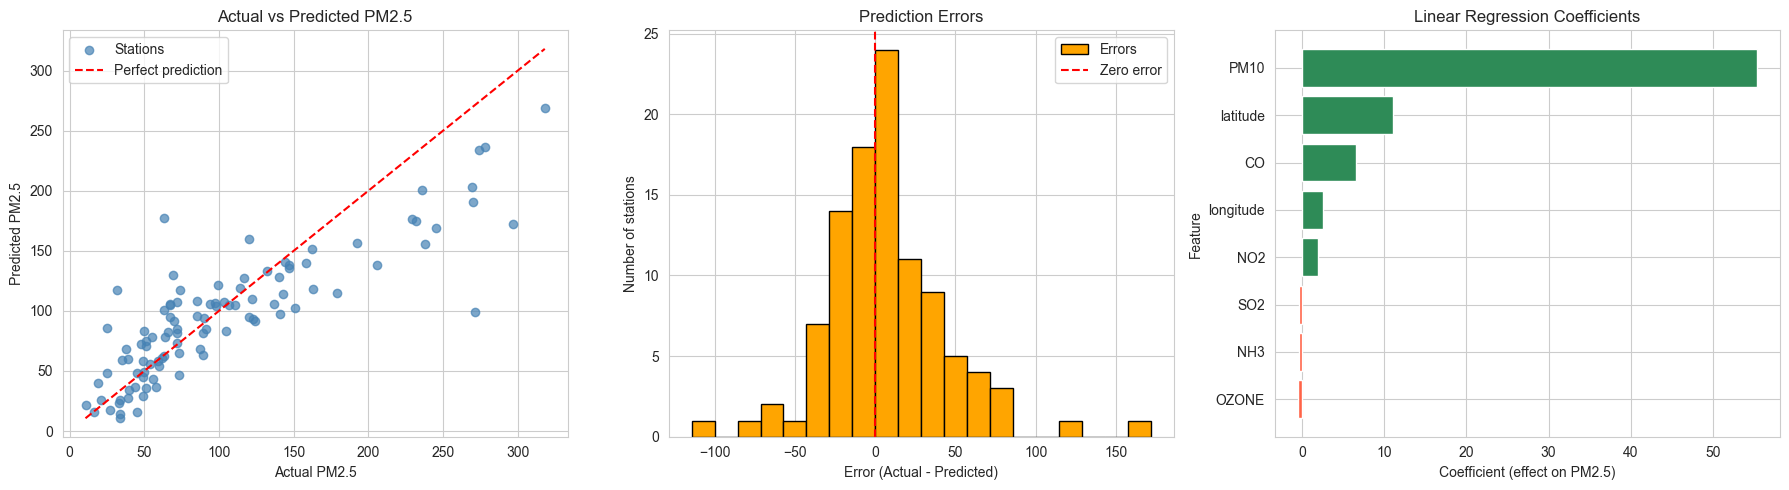

In [54]:
# Visualization of the Linear Regression results
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1) Actual vs predicted values
axes[0].scatter(y_reg_test, lin_pred, color='steelblue', alpha=0.7, label='Stations')
line_min = min(y_reg_test.min(), lin_pred.min())
line_max = max(y_reg_test.max(), lin_pred.max())
axes[0].plot([line_min, line_max], [line_min, line_max], color='red', linestyle='--', label='Perfect prediction')
axes[0].set_title('Actual vs Predicted PM2.5')
axes[0].set_xlabel('Actual PM2.5')
axes[0].set_ylabel('Predicted PM2.5')
axes[0].legend()

# 2) Errors (residuals) = actual - predicted
errors = y_reg_test - lin_pred
axes[1].hist(errors, bins=20, color='orange', edgecolor='black', label='Errors')
axes[1].axvline(0, color='red', linestyle='--', label='Zero error')
axes[1].set_title('Prediction Errors')
axes[1].set_xlabel('Error (Actual - Predicted)')
axes[1].set_ylabel('Number of stations')
axes[1].legend()

# 3) Coefficients (which feature has the biggest effect)
coef = pd.Series(lin_model.coef_, index=feature_cols).sort_values()
colors = ['seagreen' if c > 0 else 'tomato' for c in coef.values]
axes[2].barh(coef.index, coef.values, color=colors)
axes[2].set_title('Linear Regression Coefficients')
axes[2].set_xlabel('Coefficient (effect on PM2.5)')
axes[2].set_ylabel('Feature')

plt.tight_layout()
plt.show()

**Explanation of the results:**
- **R-squared = 0.71:** the model explains about 71% of the changes in PM2.5. This is a good result for a simple straight-line model.
- **MAE = 27.2:** on average, the predicted PM2.5 is about 27 units away from the real value. The average PM2.5 of the test stations is about 102, so the average error is roughly one-fourth of the typical value.
- **RMSE = 39.1** is bigger than MAE, which means a few stations have large errors. (MSE = 1526.6 is the square of RMSE.)
- **Graph 1:** the points are close to the red dashed line for many stations, so the predictions follow the real values. The points are more spread out at high PM2.5 values.
- **Graph 3:** PM10 has by far the biggest effect (the features are scaled, so the bars can be compared). This is because PM10 and PM2.5 are both particles and are strongly related. Latitude and CO have a smaller positive effect, and the other pollutants have almost no effect.

---
## Section 8: Logistic Regression (predicting the PM2.5 category)
Logistic Regression is a **classification** model. Even though its name has "regression", it predicts a **category**. It calculates the probability of each category and picks the most likely one. We use the scaled data.

**Metrics used for classification:**
- **Confusion matrix:** a table of actual vs predicted categories (the diagonal shows correct predictions).
- **Precision:** of the stations predicted as a category, how many were really in it.
- **Recall:** of the stations really in a category, how many were found.
- **F1-score:** the balance of precision and recall (higher is better). We use the *weighted* average because the six categories have different sizes.

Logistic Regression Results
Accuracy  : 0.5392
Precision : 0.4831
Recall    : 0.5392
F1-score  : 0.4892


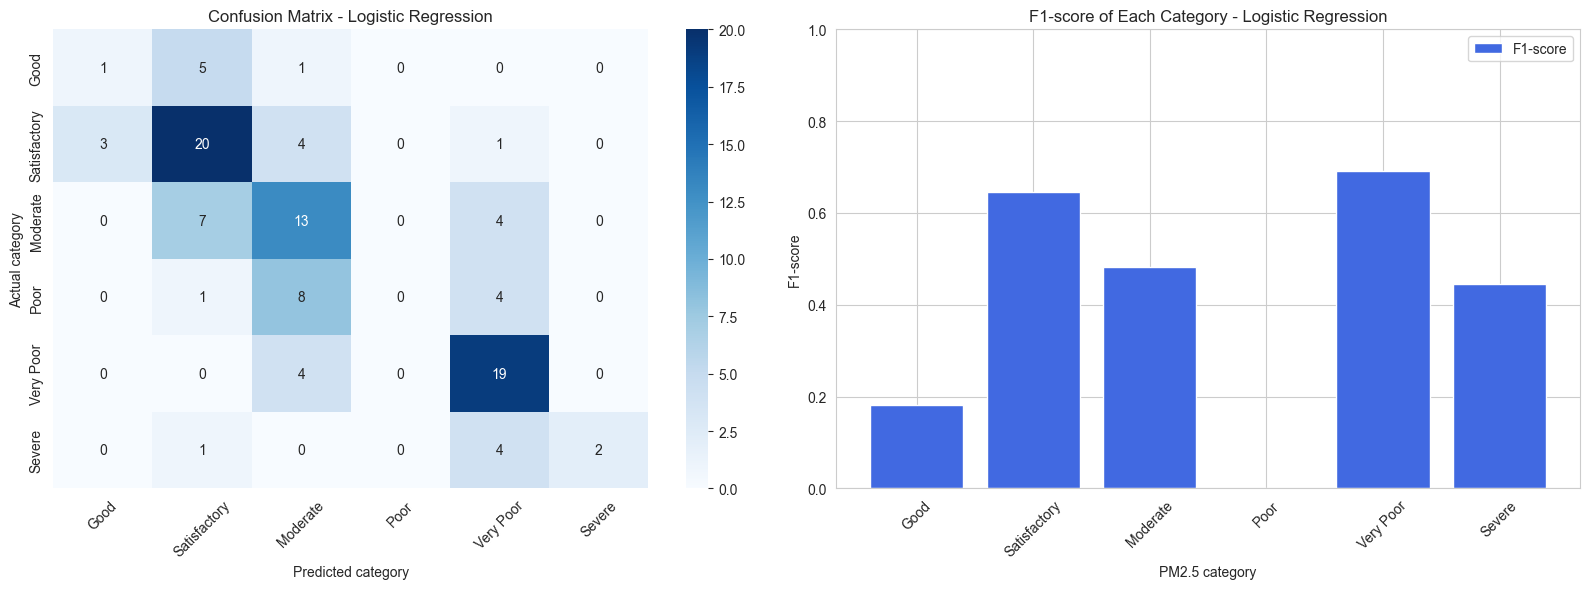

In [55]:
# Train the model
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_scaled, y_train)

# Predict on the test data
lr_pred = lr_model.predict(X_test_scaled)

# Evaluation metrics
lr_acc = accuracy_score(y_test, lr_pred)
lr_prec = precision_score(y_test, lr_pred, average='weighted', zero_division=0)
lr_rec = recall_score(y_test, lr_pred, average='weighted', zero_division=0)
lr_f1 = f1_score(y_test, lr_pred, average='weighted', zero_division=0)

print('Logistic Regression Results')
print('Accuracy  :', round(lr_acc, 4))
print('Precision :', round(lr_prec, 4))
print('Recall    :', round(lr_rec, 4))
print('F1-score  :', round(lr_f1, 4))


# Confusion matrix and F1-score of each category
lr_cm = confusion_matrix(y_test, lr_pred, labels=class_names)
lr_f1_each = f1_score(y_test, lr_pred, average=None, labels=class_names, zero_division=0)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(lr_cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title('Confusion Matrix - Logistic Regression')
axes[0].set_xlabel('Predicted category')
axes[0].set_ylabel('Actual category')
axes[0].tick_params(axis='x', rotation=45)

axes[1].bar(class_names, lr_f1_each, color='royalblue', label='F1-score')
axes[1].set_title('F1-score of Each Category - Logistic Regression')
axes[1].set_xlabel('PM2.5 category')
axes[1].set_ylabel('F1-score')
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend()

plt.tight_layout()
plt.show()

**Explanation of the results:**
- The confusion matrix shows that the model is best at *Satisfactory*, *Moderate* and *Very Poor* stations. Most of the mistakes are between **neighbouring categories** (for example Moderate and Poor, or Poor and Very Poor), which is natural because the categories are made from one continuous number.
- The F1-score graph shows that the model is weak for the **Good** category and fails for the **Poor** category (F1 = 0). The model never predicted "Poor" for any test station.
- The *Good*, *Poor* and *Severe* categories have fewer stations, so the model has fewer examples to learn from.

---
## Section 9: K-Nearest Neighbors (KNN)
KNN is a very simple classification model. To predict the category of a station, it looks at the **k most similar stations** in the training data (the nearest neighbours) and takes a **vote**. Because it uses distances, the data must be scaled.

The best value of **k** is chosen using **cross-validation on the training data only** (the test data is kept untouched).

Best k from cross-validation: 14


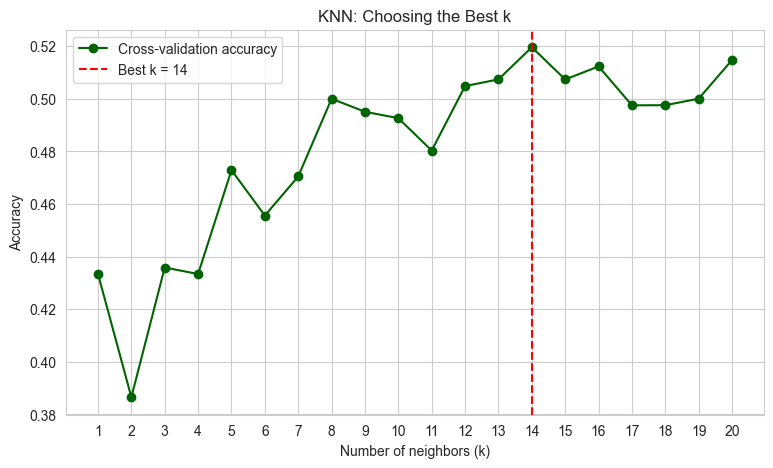

In [56]:
# Find the best k using 5-fold cross-validation on the TRAINING data
k_list = list(range(1, 21))
cv_scores = []
for k in k_list:
    knn_temp = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn_temp, X_train_scaled, y_train, cv=5, scoring='accuracy')
    cv_scores.append(scores.mean())

best_k = k_list[cv_scores.index(max(cv_scores))]
print('Best k from cross-validation:', best_k)

plt.figure(figsize=(9, 5))
plt.plot(k_list, cv_scores, marker='o', color='darkgreen', label='Cross-validation accuracy')
plt.axvline(best_k, color='red', linestyle='--', label='Best k = ' + str(best_k))
plt.title('KNN: Choosing the Best k')
plt.xlabel('Number of neighbors (k)')
plt.ylabel('Accuracy')
plt.xticks(k_list)
plt.legend()
plt.show()

KNN Results (k = 14 )
Accuracy  : 0.5392
Precision : 0.5007
Recall    : 0.5392
F1-score  : 0.4828


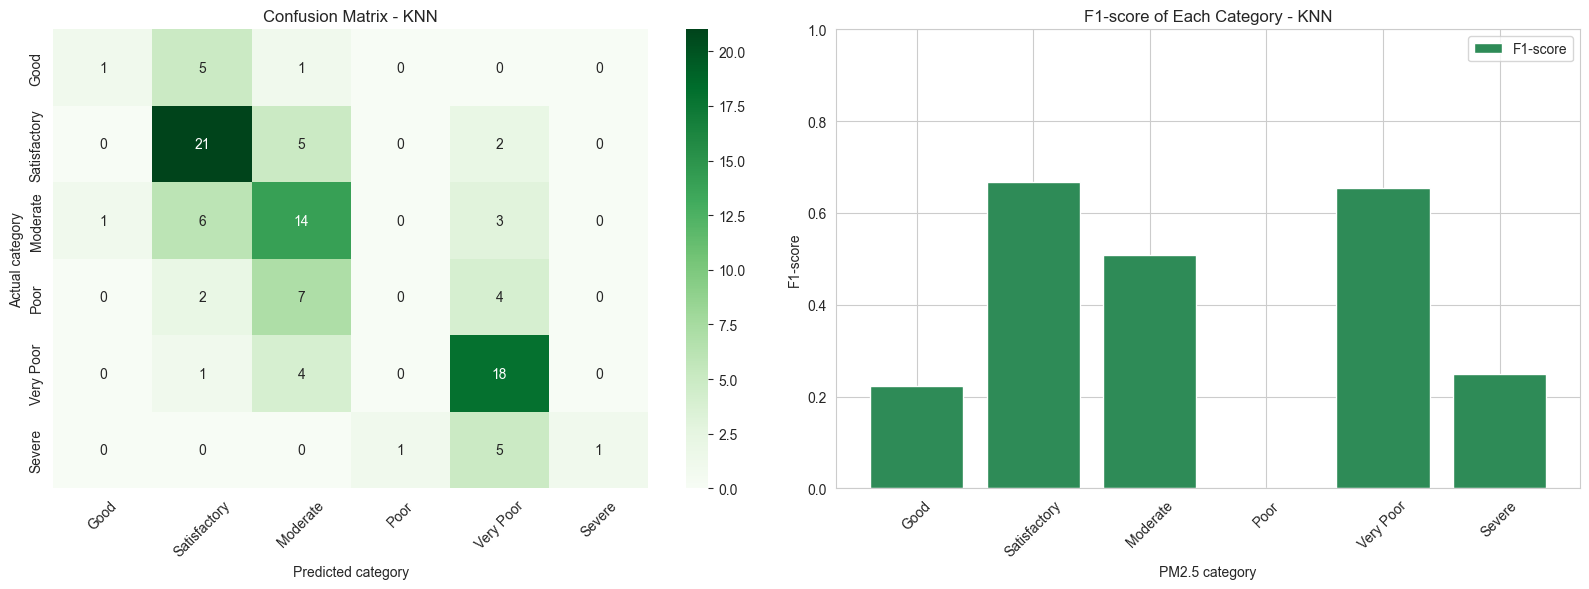

In [57]:
# Train the final KNN model with the best k
knn_model = KNeighborsClassifier(n_neighbors=best_k)
knn_model.fit(X_train_scaled, y_train)

# Predict on the test data
knn_pred = knn_model.predict(X_test_scaled)

# Evaluation metrics
knn_acc = accuracy_score(y_test, knn_pred)
knn_prec = precision_score(y_test, knn_pred, average='weighted', zero_division=0)
knn_rec = recall_score(y_test, knn_pred, average='weighted', zero_division=0)
knn_f1 = f1_score(y_test, knn_pred, average='weighted', zero_division=0)

print('KNN Results (k =', best_k, ')')
print('Accuracy  :', round(knn_acc, 4))
print('Precision :', round(knn_prec, 4))
print('Recall    :', round(knn_rec, 4))
print('F1-score  :', round(knn_f1, 4))


# Confusion matrix and F1-score of each category
knn_cm = confusion_matrix(y_test, knn_pred, labels=class_names)
knn_f1_each = f1_score(y_test, knn_pred, average=None, labels=class_names, zero_division=0)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(knn_cm, annot=True, fmt='d', cmap='Greens', xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title('Confusion Matrix - KNN')
axes[0].set_xlabel('Predicted category')
axes[0].set_ylabel('Actual category')
axes[0].tick_params(axis='x', rotation=45)

axes[1].bar(class_names, knn_f1_each, color='seagreen', label='F1-score')
axes[1].set_title('F1-score of Each Category - KNN')
axes[1].set_xlabel('PM2.5 category')
axes[1].set_ylabel('F1-score')
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend()

plt.tight_layout()
plt.show()

**Explanation of the results:**
- The best k was found by cross-validation (the graph shows that accuracy is lower for very small k and becomes better for bigger k).
- Like Logistic Regression, KNN is good at the *Satisfactory*, *Moderate* and *Very Poor* categories, and its mistakes are mostly between neighbouring categories.
- KNN also finds it hard to predict the **Poor** category (F1 = 0) and the **Good** and **Severe** categories, which have few examples.

---
## Section 10: Decision Tree Classifier (predicting the PM2.5 category)
A Decision Tree is a **classification** model that asks a series of yes/no questions about the features (for example "is PM10 less than 100?") to reach a decision, just like a flow chart. It does not need scaled data, so we use the filled (imputed) but unscaled data. We set `max_depth = 4` so that the tree stays small, easy to read, and does not memorise the training data.

Decision Tree Results
Accuracy  : 0.5098
Precision : 0.4911
Recall    : 0.5098
F1-score  : 0.4913


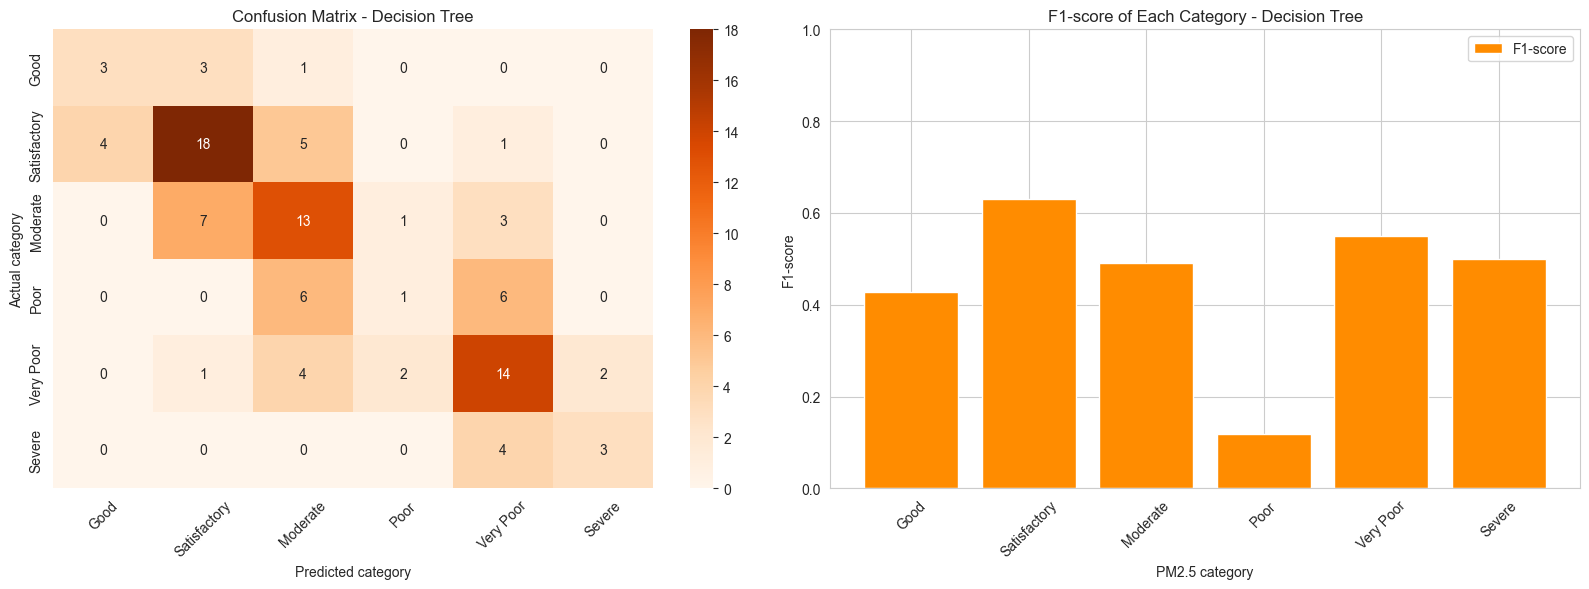

In [58]:
# Train the model (scaling is not needed for a tree)
dt_model = DecisionTreeClassifier(max_depth=4, random_state=42)
dt_model.fit(X_train_imp, y_train)

# Predict on the test data
dt_pred = dt_model.predict(X_test_imp)

# Evaluation metrics
dt_acc = accuracy_score(y_test, dt_pred)
dt_prec = precision_score(y_test, dt_pred, average='weighted', zero_division=0)
dt_rec = recall_score(y_test, dt_pred, average='weighted', zero_division=0)
dt_f1 = f1_score(y_test, dt_pred, average='weighted', zero_division=0)

print('Decision Tree Results')
print('Accuracy  :', round(dt_acc, 4))
print('Precision :', round(dt_prec, 4))
print('Recall    :', round(dt_rec, 4))
print('F1-score  :', round(dt_f1, 4))

# Confusion matrix and F1-score of each category
dt_cm = confusion_matrix(y_test, dt_pred, labels=class_names)
dt_f1_each = f1_score(y_test, dt_pred, average=None, labels=class_names, zero_division=0)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(dt_cm, annot=True, fmt='d', cmap='Oranges', xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title('Confusion Matrix - Decision Tree')
axes[0].set_xlabel('Predicted category')
axes[0].set_ylabel('Actual category')
axes[0].tick_params(axis='x', rotation=45)

axes[1].bar(class_names, dt_f1_each, color='darkorange', label='F1-score')
axes[1].set_title('F1-score of Each Category - Decision Tree')
axes[1].set_xlabel('PM2.5 category')
axes[1].set_ylabel('F1-score')
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend()

plt.tight_layout()
plt.show()

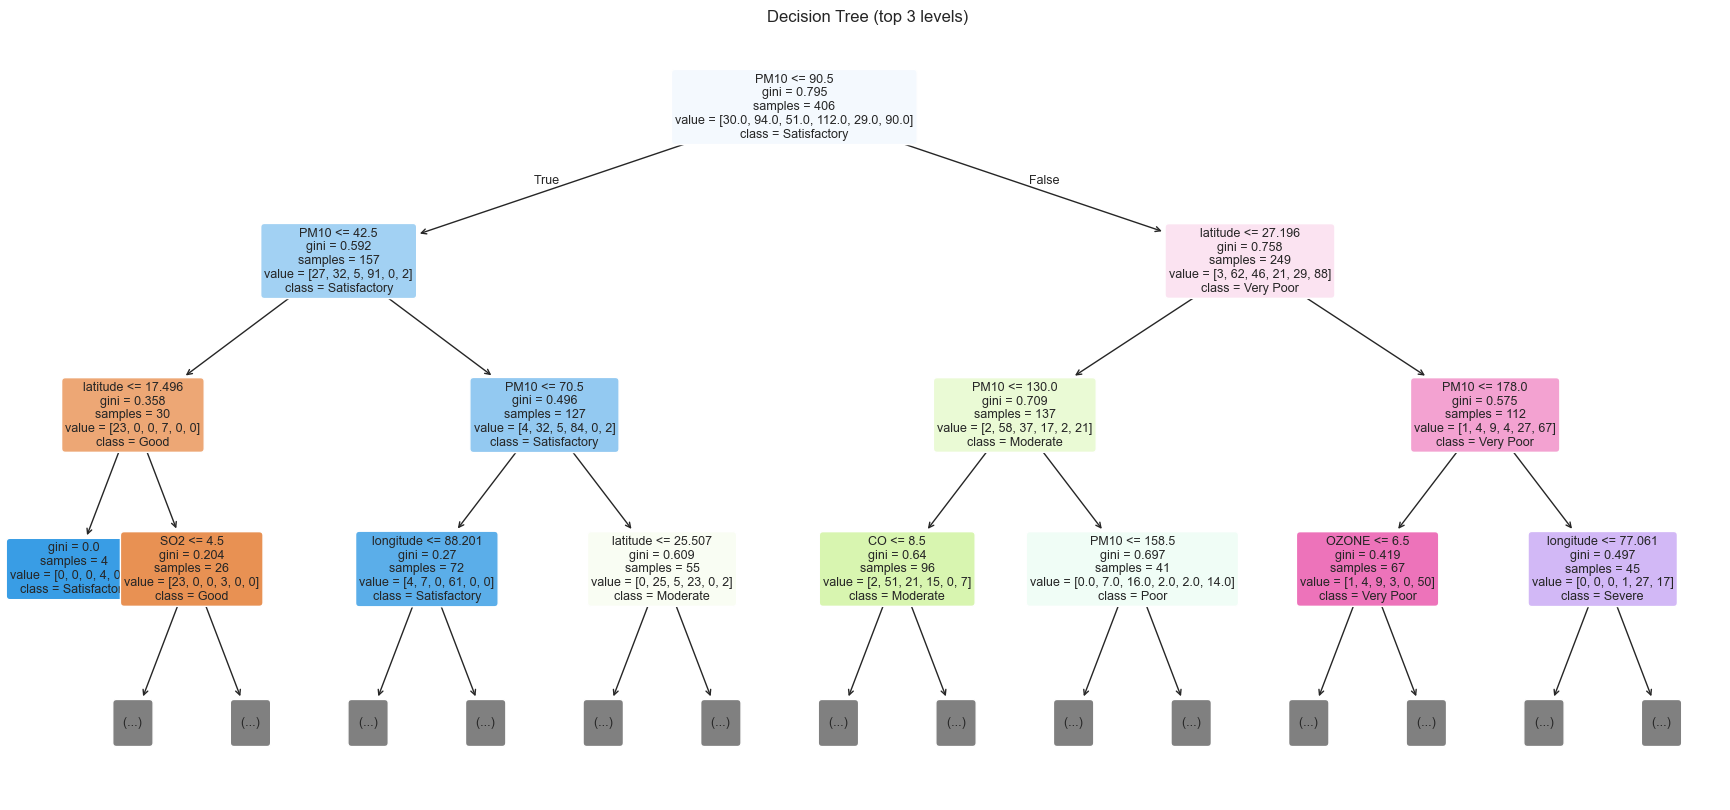

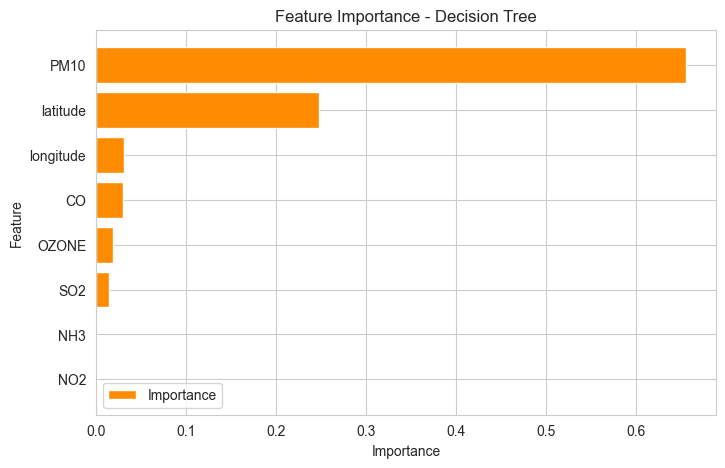

In [59]:
# Picture of the decision tree (first 3 levels only, so that it is easy to read)
plt.figure(figsize=(22, 10))
plot_tree(dt_model, feature_names=feature_cols, class_names=list(dt_model.classes_),
          filled=True, rounded=True, max_depth=3, fontsize=9)
plt.title('Decision Tree (top 3 levels)')
plt.show()

# Which features were most important for the tree?
importance = pd.Series(dt_model.feature_importances_, index=feature_cols).sort_values()
plt.figure(figsize=(8, 5))
plt.barh(importance.index, importance.values, color='darkorange', label='Importance')
plt.title('Feature Importance - Decision Tree')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.legend()
plt.show()

**Explanation of the results:**
- The Decision Tree has an accuracy of 0.510 and an F1-score of 0.491. The accuracy is a little lower than Logistic Regression and KNN, and the F1-score is about the same.
- Unlike the other two models, the tree finds some stations of the **Good**, **Poor** and **Severe** categories (see the F1-score graph). It is weaker on *Very Poor* than the other two models.
- The tree picture shows the questions in order. The feature importance graph shows that **PM10 is by far the most important feature** (about 66%), followed by **latitude** (about 25%), which is the location of the station. The other pollutants are used very little.
- As in the other models, most mistakes happen between neighbouring categories.

---
## Section 11: K-Means Clustering
K-Means is **unsupervised**: it does not use any target labels. It groups stations with similar pollutant levels into `k` clusters. We use all seven pollutants (including PM2.5, because there is no target here) and only the stations that have **all seven readings**, so no values need to be filled. The data is scaled first, because K-Means uses distances.

First we use the **elbow method** to choose `k`.

Stations used for clustering: 414


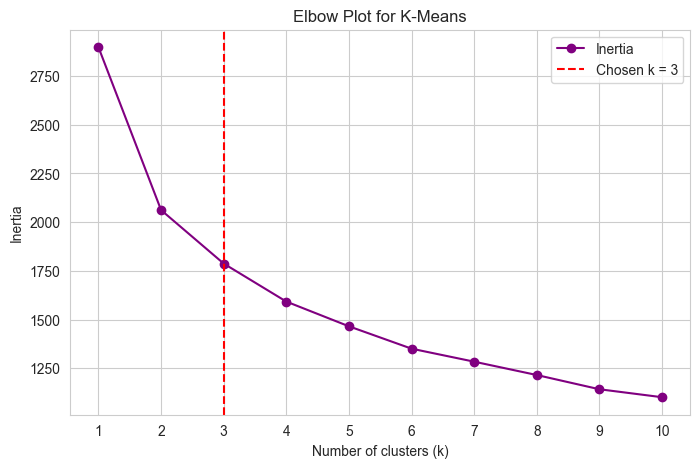

In [60]:
# Stations that have a reading for all 7 pollutants
cluster_data = wide.dropna(subset=pollutants).copy()
print('Stations used for clustering:', len(cluster_data))

# Scale the data
cluster_scaled = StandardScaler().fit_transform(cluster_data[pollutants])

# Elbow method: try k = 1 to 10 and note the inertia (within-cluster distance)
inertia = []
k_values = range(1, 11)
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(cluster_scaled)
    inertia.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia, marker='o', color='purple', label='Inertia')
plt.axvline(3, color='red', linestyle='--', label='Chosen k = 3')
plt.title('Elbow Plot for K-Means')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.xticks(list(k_values))
plt.legend()
plt.show()

**Choosing k:** The elbow in the graph is not very sharp. The curve bends gently around k = 3, and k = 3 also gives three clear and meaningful groups (explained below), so we use **k = 3**.

Number of stations in each K-Means cluster:
KMeans_Cluster
0    235
1     93
2     86
Name: count, dtype: int64

Average pollutant values in each cluster:
                PM2.5   PM10   NO2   SO2    CO  OZONE  NH3
KMeans_Cluster                                            
0                66.2   78.9  19.3  15.1  30.9   22.1  3.8
1                92.1  112.7  34.9  10.2  33.5   68.7  7.0
2               208.8  192.4  56.7  20.2  60.6   39.7  8.0


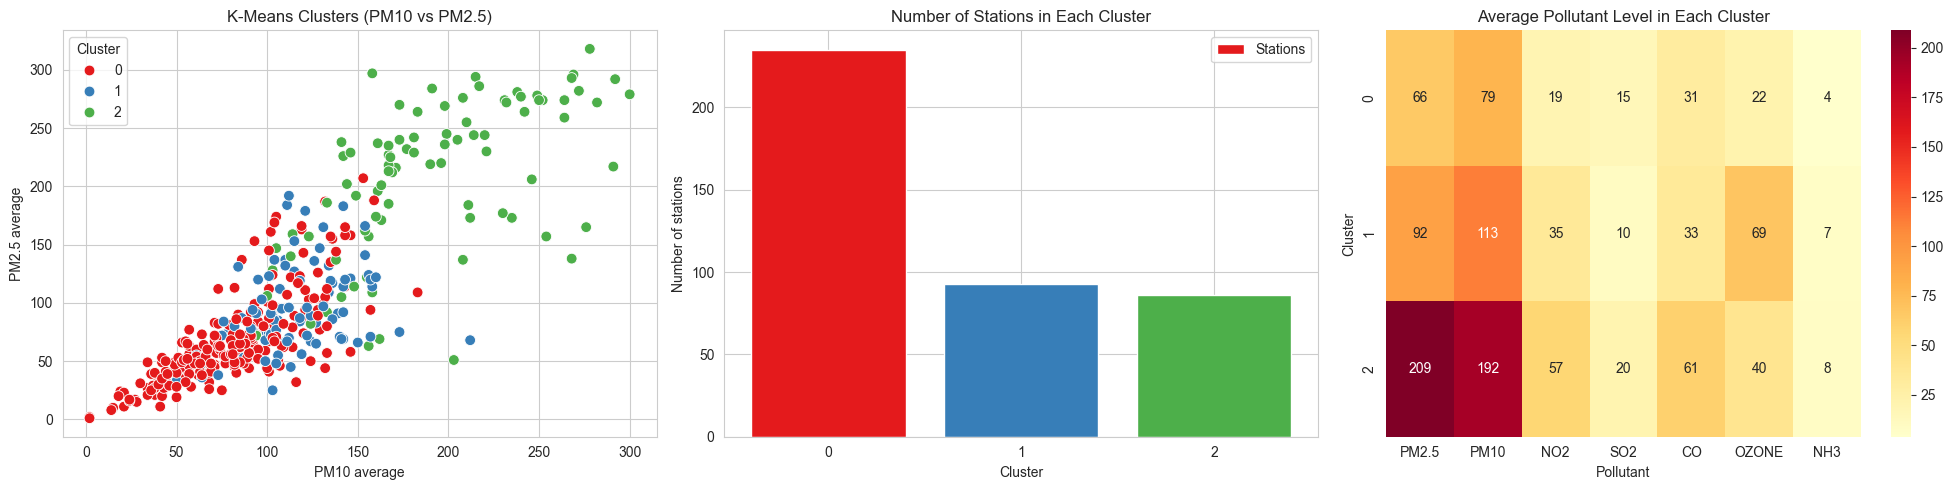

In [61]:
# Apply K-Means with k = 3
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
cluster_data['KMeans_Cluster'] = kmeans.fit_predict(cluster_scaled)

# Number of records (stations) in each cluster
cluster_sizes = cluster_data['KMeans_Cluster'].value_counts().sort_index()
print('Number of stations in each K-Means cluster:')
print(cluster_sizes)

# Average pollutant values in each cluster (this helps us understand the clusters)
cluster_profile = cluster_data.groupby('KMeans_Cluster')[pollutants].mean()
print('\nAverage pollutant values in each cluster:')
print(cluster_profile.round(1))

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# 1) Clusters on a scatter plot (PM10 vs PM2.5)
sns.scatterplot(data=cluster_data, x='PM10', y='PM2.5', hue='KMeans_Cluster', palette='Set1', s=60, ax=axes[0])
axes[0].set_title('K-Means Clusters (PM10 vs PM2.5)')
axes[0].set_xlabel('PM10 average')
axes[0].set_ylabel('PM2.5 average')
axes[0].legend(title='Cluster')

# 2) Number of stations in each cluster
axes[1].bar(cluster_sizes.index.astype(str), cluster_sizes.values, color=['#e41a1c', '#377eb8', '#4daf4a'], label='Stations')
axes[1].set_title('Number of Stations in Each Cluster')
axes[1].set_xlabel('Cluster')
axes[1].set_ylabel('Number of stations')
axes[1].legend()

# 3) Average pollutant level in each cluster
sns.heatmap(cluster_profile, annot=True, fmt='.0f', cmap='YlOrRd', ax=axes[2])
axes[2].set_title('Average Pollutant Level in Each Cluster')
axes[2].set_xlabel('Pollutant')
axes[2].set_ylabel('Cluster')

plt.tight_layout()
plt.show()

**What the K-Means clusters mean:** (see the heatmap and the table of averages above)
- **Low-pollution cluster (largest group, 235 stations):** lowest PM2.5 and PM10 and low NO2 and OZONE. These are the relatively cleaner stations.
- **High-ozone cluster (93 stations):** moderate-to-high PM values with the highest OZONE and a higher NO2 than the first group.
- **Heavily polluted cluster (86 stations):** very high PM2.5 and PM10 (about 200) and also the highest CO, NO2 and SO2. These are the most polluted stations.

The cluster numbers (0, 1, 2) are just labels given by the algorithm; they do not have any order.

---
## Section 12: Conclusion

**Main findings from EDA**
- 546 stations in 282 cities were in the snapshot, and 508 of them had a PM2.5 reading.
- PM2.5 and PM10 are the most serious pollutants. Their average values are about 103 and 112, and they are strongly correlated (about 0.86).
- About 29% of the stations with PM2.5 readings are in the *Very Poor* or *Severe* categories (149 of 508).
- Cities with the highest average PM2.5 include Panipat, Khora, Kiul, Panchgaon, Noida and Delhi. Cities such as Cuttack, Balasore and Korba have the lowest values. Many of these cities have only one station.

**Regression (Linear Regression)**
- R-squared is 0.71, MAE is 27.2 and RMSE is 39.1, so the PM2.5 value can be estimated reasonably well from the other pollutants. PM10 is the most important feature.

**Classification (Logistic Regression, KNN and Decision Tree)**
- Logistic Regression and KNN both have an accuracy of 0.539 (F1-scores 0.489 and 0.483). The Decision Tree has an accuracy of 0.510 and an F1-score of 0.491. All three models perform about the same.
- All models find the *Poor* category very hard and are weaker on *Good* and *Severe*, because these categories have few stations. The Decision Tree handles these small categories a little better.
- In the Decision Tree, PM10 and latitude are the most important features.

**What K-Means shows**
- K-Means splits the 414 stations into three types: low-pollution stations (235), high-ozone stations (93) and heavily polluted stations with very high PM2.5, PM10, CO and NO2 (86).

**Limitations**
- The data is only **one snapshot**, so it cannot show trends or seasons, and this project does **not** forecast future pollution.
- There are only 508 labelled stations, and some categories have very few examples.
- PM10 is a strong hint for PM2.5, and the models are limited by the small data size.
- The categories use the AQI thresholds on a single average reading, not the official 24-hour average.
- Some pollutant readings are missing, and many cities have only one station.

**Possible future improvements**
- Collect data for many days or months to study trends.
- Try hyperparameter tuning and more cross-validation.
- Add weather data (temperature, wind, humidity) as new features.
- Use the real AQI formula with 24-hour averages.